In [ ]:
import geopandas as gpd
import h3
import matplotlib as mpl
import matplotlib.pyplot as plt
import polars as pl
import yaml
from shapely import Polygon
from cmcrameri import cm

mpl.rcParams["svg.hashsalt"] = "42"

with open("plotting_config.yaml", "r") as fp:
    config = yaml.safe_load(fp)


def add_geometry(x: str):
    """create hex geometry"""
    points = ((i[1], i[0]) for i in h3.cell_to_boundary(x))
    return Polygon(points)


def sum_locations_in_hexagons(data: pl.DataFrame, column: str):
    count = (
        data.group_by(column)
        .agg(pl.col.device_id.count())
        .rename({"device_id": "count"})
    )
    return count

In [23]:
# DIR = f"../data/pickwell/cleaned/pickwell-sample-data/{CITY}/{VARIANT}"
OUTPUT = "../output/"

In [ ]:
census8 = pl.read_csv(
    "/mnt/common-hdd/group-dirs/tkom-2026-project/census/h3_8_grouped.csv"
)

In [24]:
hw = pl.read_csv(f"{OUTPUT}/home_work_00_settlement.csv")
hw8 = pl.read_csv(f"{OUTPUT}/home_work_00_h3_8.csv")

In [33]:
home_count_8 = sum_locations_in_hexagons(hw8, "h3_8_home")
work_count_8 = sum_locations_in_hexagons(hw8, "h3_8_work")


In [35]:
home_count_8

h3_8_home,count
str,u32
"""881e036301fffff""",4
"""881e1cb609fffff""",1
"""881e037abdfffff""",29
"""881e036167fffff""",1
"""881e0361b1fffff""",2
…,…
"""881e037aa1fffff""",55
"""881e036223fffff""",9
"""881e037a89fffff""",5


In [36]:
h8 = gpd.read_file("../data/h3/budapest/8.geojson")

In [66]:
h8_homes = h8.merge(
    home_count_8.rename({"h3_8_home": "h3"}).to_pandas(), on="h3", how="left"
).fillna(0)


In [ ]:
corr = (
    pl.from_pandas(h8_homes[["h3", "count"]])
    .join(census8.rename({"h3_id": "h3"}), on="h3")
    .select(pl.corr("count", "pop", method="pearson"))["count"][0]
)
corr

0.7184533498434256

In [79]:
census8[["h3_id", "pop"]].rename({"h3_id": "h3"}).to_pandas()

,h3,pop
0,881e034483fffff,5.0
1,881e034491fffff,19.0
2,881e034493fffff,238.0
3,881e034495fffff,370.0
4,881e034497fffff,930.0
...,...,...
612,881e1cb6d5fffff,188.0
613,881e1cb6d7fffff,1442.0
614,881e1cb6d9fffff,170.0
615,881e1cb6dbfffff,1127.0


In [80]:
h8.merge(
    census8[["h3_id", "pop"]].rename({"h3_id": "h3"}).to_pandas(), on="h3", how="left"
).fillna(0)

,h3,geometry,pop
0,881e03783bfffff,"POLYGON ((19.0325 47.46923, 19.03008 47.46478,...",6852.0
1,881e037a0bfffff,"POLYGON ((18.99941 47.54316, 18.99698 47.53871...",279.0
2,881e0379d5fffff,"POLYGON ((19.02992 47.44, 19.02749 47.43554, 1...",1950.0
3,881e0379d9fffff,"POLYGON ((19.03719 47.45335, 19.03477 47.4489,...",5144.0
4,881e037aa7fffff,"POLYGON ((19.05904 47.49341, 19.05661 47.48896...",11489.0
...,...,...,...
698,881e0344b5fffff,"POLYGON ((18.98037 47.56946, 18.97795 47.56501...",6.0
699,881e03798dfffff,"POLYGON ((19.01068 47.42916, 19.00826 47.42471...",2704.0
700,881e036a05fffff,"POLYGON ((19.09673 47.40353, 19.0943 47.39907,...",2087.0
701,881e037189fffff,"POLYGON ((19.13873 47.56587, 19.1363 47.56143,...",0.0


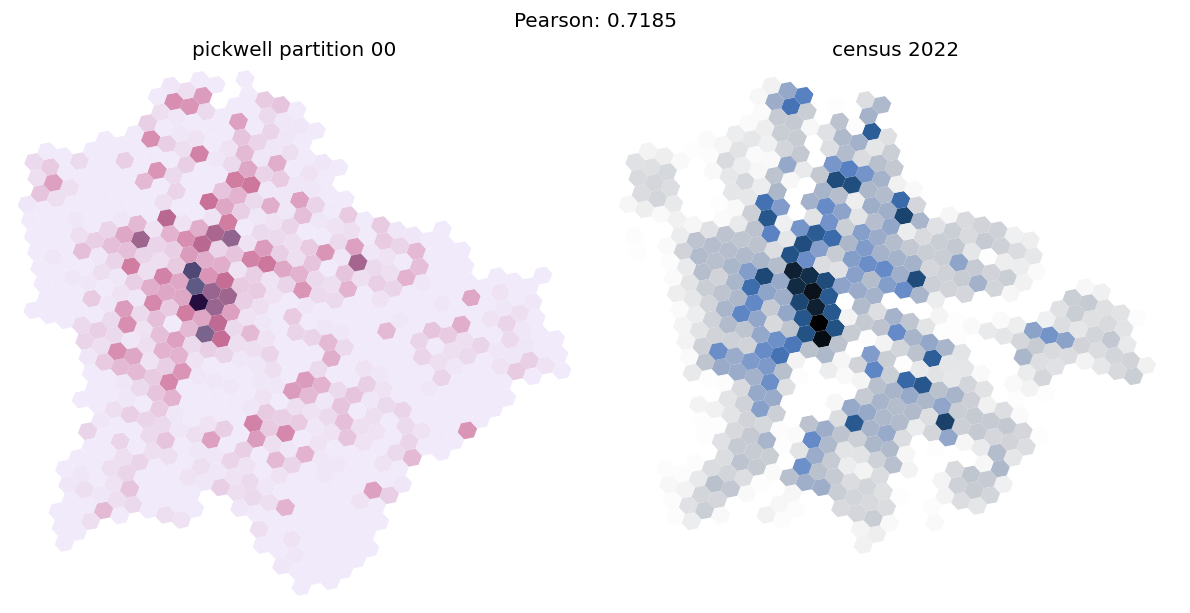

In [90]:
fig, axs = plt.subplots(layout="constrained", ncols=2, figsize=(10, 5), dpi=120)
h8_homes.to_crs(23700).plot(ax=axs[0], column="count", cmap=cm.acton_r)
axs[0].set_title("pickwell partition 00")
axs[1].set_title("census 2022")
fig.suptitle(f"Pearson: {corr:0.04f}")
h8.merge(
    census8[["h3_id", "pop"]].rename({"h3_id": "h3"}).to_pandas(), on="h3", how="left"
).fillna(0).to_crs(23700).plot(ax=axs[1], column="pop", cmap=cm.oslo_r)
for i in range(2):
    axs[i].margins(0.01)
    _ = axs[i].axis("off")
for i in config["formats"]:
    fig.savefig(
        f"../output/figures/detected_population_00.{i}",
        pad_inches=0,
        metadata=config["metadata"][i],
    )